### This notebook trains and evaluates a phone classification model.
- This notebook loads the encoded PD1 phone dataset.

- We use the mini_10_min corpus to test the code first.

- We train a simple MLP classifier on the dataset.

- We choose one training split at each time, such as `train_25`, `train_50`, `train_75`, or `train_100`.

- After training, we evaluate the best model on the test set and saves the results, confusion matrix, then we analyze the performances.

In [1]:
import os
import json
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from datetime import datetime
from datasets import DatasetDict, load_from_disk
from torch.utils.data import DataLoader

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec

#### Remember to restart kernel after each run


### __Part I : Data Preparation__


In [2]:
# encoded_subsets = load_from_disk("../dataset/mel/PD1_phone_mel_subsets_encoded")
encoded_subsets = load_from_disk("../dataset/mfcc/PD1_phone_mfcc_subsets_encoded")

- Here, we choose which training subset to use. The validation and test sets stay the same, while only the training set size changes.

- This allows us to compare how training data size affects model performance.

In [3]:
# train_split_name = "train_mini_10min" # only for testing the code
# train_split_name = "train_25"
# train_split_name = "train_50"
train_split_name = "train_75"
# train_split_name = "train_100"

- This section defines the main training parameters.

- `use_mini_evaluation=True` uses smaller validation and test sets for quick debugging. For further experiments, `use_mini_evaluation` should be set to `False`.

In [4]:
# initializing the parameters
use_mini_evaluation = False # using mini eval dataset for testing the status of the code

batch_size_train = 256
batch_size_eval = 256

num_hidden=50
learning_rate = 0.001
EPOCHS = 8

seed = 42

In [5]:
# set random seeds to make the experiment more reproducible
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

In [6]:
# selects the available computing device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)

Device: mps


In [7]:
# check whether the selected training split exists before training
available_train_splits = {
    "train_mini_10min",
    "train_25",
    "train_50",
    "train_75",
    "train_100",
}

if train_split_name not in available_train_splits:
    raise ValueError(
        f"Unknown training split: {train_split_name}. Available splits: {sorted(available_train_splits)}")

- This section prepares the validation and test datasets.

- If mini evaluation is enabled, only up to 5000 samples are selected from validation and test. Otherwise, the full validation and test sets are used.

In [8]:
if use_mini_evaluation:
    # avoid selecting more samples than the dataset contains
    mini_validation_size = min(5000, len(encoded_subsets["validation"])) # avoid org. validation and test set smaller than 5000
    mini_test_size = min(5000, len(encoded_subsets["test"]))

    validation_dataset = (encoded_subsets["validation"].shuffle(seed=seed).select(range(mini_validation_size)))
    test_dataset = (encoded_subsets["test"].shuffle(seed=seed).select(range(mini_test_size)))
    
else:
    validation_dataset = encoded_subsets["validation"]
    test_dataset = encoded_subsets["test"]

In [9]:
# combine the selected train, validation, and test splits into one DatasetDict
ds_dict = DatasetDict({
    "train": encoded_subsets[train_split_name],
    "validation": validation_dataset,
    "test": test_dataset,
})

print(ds_dict)
print(ds_dict["train"][0])

DatasetDict({
    train: Dataset({
        features: ['feat', 'frame_index', 'utt_id', 'speaker_uid', 'volume', 'speaker_id', 'recording_site', 'sex', 'age', 'pd2', 'phones', 'label'],
        num_rows: 4177793
    })
    validation: Dataset({
        features: ['feat', 'frame_index', 'utt_id', 'speaker_uid', 'volume', 'speaker_id', 'recording_site', 'sex', 'age', 'pd2', 'phones', 'label'],
        num_rows: 599109
    })
    test: Dataset({
        features: ['feat', 'frame_index', 'utt_id', 'speaker_uid', 'volume', 'speaker_id', 'recording_site', 'sex', 'age', 'pd2', 'phones', 'label'],
        num_rows: 1515136
    })
})
{'feat': [-398.6270446777, 23.880443573, 11.0410995483, 8.5946426392, 11.926109314, 8.0008134842, 10.0552330017, 9.0858068466, 2.7410740852, 6.7106490135, 7.388130188, 3.0973353386, -2.5346076488], 'frame_index': 41, 'utt_id': 'm75a4380', 'speaker_uid': 'M75A', 'volume': '3', 'speaker_id': 'M75', 'recording_site': 'A', 'sex': 'M', 'age': 'A', 'pd2': '', 'phones': '<

- Here, we read the label information and feature dimension from the dataset.

- `num_feat` is the input dimension of the model, for example 32 for Mel features. `num_classes` is the number of phone classes.

In [10]:
label_feature = ds_dict["train"].features["label"]
num_feat = len(ds_dict["train"][0]["feat"])

num_classes = label_feature.num_classes
phone_names = label_feature.names

print("Feature dimension:", num_feat)
print("Number of phone classes:", num_classes)
print("Phone names:", phone_names)

Feature dimension: 13
Number of phone classes: 44
Phone names: ['2:', '6', '9', '<p:>', '?', '@', 'C', 'E', 'E:', 'I', 'N', 'O', 'OY', 'S', 'U', 'Y', 'Z', 'a', 'a:', 'aI', 'aU', 'a~', 'b', 'd', 'e:', 'f', 'g', 'h', 'i:', 'j', 'k', 'l', 'm', 'n', 'o:', 'p', 'r', 's', 't', 'u:', 'v', 'x', 'y:', 'z']


In [11]:
# convert selected columns to PyTorch tensors
ds_dict = ds_dict.with_format(type="torch", columns=["feat", "label"])

- This section creates PyTorch DataLoaders.

- The training loader shuffles the data. The validation and test loaders do not shuffle, because evaluation does not require random order.

In [12]:
loader_generator = torch.Generator()
loader_generator.manual_seed(seed) # make sure the reproducability of the project

training_loader = torch.utils.data.DataLoader(
    ds_dict["train"],
    batch_size=batch_size_train,
    shuffle=True, generator=loader_generator
)

validation_loader = torch.utils.data.DataLoader(
    ds_dict["validation"],
    batch_size=batch_size_eval,
    shuffle=False
)

test_loader = torch.utils.data.DataLoader(
    ds_dict["test"],
    batch_size=batch_size_eval,
    shuffle=False
)

### __Part II : MLP Model__

- We use a simple multi-layer perceptron for frame-level phone classification.

- The model takes one feature vector as input and predicts one phone class.

- It has one hidden layer with ReLU activation, one hidden layer makes predictions to n_classes.

In [13]:
class MLP(nn.Module):
    def __init__(self, num_feat, num_classes, num_hidden):
        super().__init__()
        self.fc1 = nn.Linear(num_feat, num_hidden)
        self.fc2 = nn.Linear(num_hidden, num_classes)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x

In [14]:
# initialize model, loss function, and optimizer
torch.manual_seed(seed)

model = MLP(num_feat=num_feat, num_classes=num_classes, num_hidden=num_hidden).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

print(model)

MLP(
  (fc1): Linear(in_features=13, out_features=50, bias=True)
  (fc2): Linear(in_features=50, out_features=44, bias=True)
)


- This function trains the model for one epoch.

- For each batch, it computes predictions, calculates loss, performs backpropagation, and updates model parameters.

- The function returns the average training loss for the epoch.

In [15]:
def train_one_epoch():
    model.train() # this MLP is without dropout, but still we add the model.train() here

    total_loss = 0.0 # total loss in this epoch
    total_samples = 0 # how many samples are trained in this epoch

    for batch_index, data in enumerate(training_loader):
        inputs = data["feat"].to(device=device, dtype=torch.float32) # get mel feature

        labels = data["label"].to(device=device, dtype=torch.long) 

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = loss_fn(outputs, labels)

        loss.backward()
        optimizer.step()

        # weight the batch loss by batch size, because the last batch may be smaller
        current_batch_size = labels.size(0)
        total_loss += (loss.item() * current_batch_size)

        total_samples += current_batch_size

        if (batch_index + 1) % 100 == 0:
            print(f"Batch {batch_index + 1}: loss = {loss.item():.4f}")

    average_loss = total_loss / total_samples
    
    return average_loss

- This function evaluates the model on the validation set. It calculates both validation loss and validation accuracy.

- `torch.no_grad()` is used because no parameter updates are needed during evaluation.

In [16]:
def validate():
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for data in validation_loader:
            inputs = data["feat"].to(device=device, dtype=torch.float32)

            labels = data["label"].to(device=device, dtype=torch.long)

            outputs = model(inputs)
            loss = loss_fn(outputs, labels)

            predictions = outputs.argmax(dim=1)

            current_batch_size = labels.size(0)

            total_loss += (loss.item() * current_batch_size)

            total_correct += (predictions == labels).sum().item()

            total_samples += current_batch_size

    average_loss = total_loss / total_samples

    accuracy = total_correct / total_samples

    return average_loss, accuracy

- Before training, we create a unique output folder for this experiment.

- The folder name stores the feature type, training split, evaluation mode, and timestamp. The best model checkpoint will be saved in this folder.

In [17]:
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# models_save_dir = "../model_for_mel/models"
models_save_dir = "../model_for_mfcc/models"

evaluation_name = ("mini_eval" if use_mini_evaluation else "full_eval")

# model_name = (f"mel_{train_split_name}_{evaluation_name}_{timestamp}")
model_name = (f"mfcc_{train_split_name}_{evaluation_name}_{timestamp}")

model_directory = os.path.join(models_save_dir, model_name)

os.makedirs(model_directory, exist_ok=False)

best_model_path = os.path.join(model_directory,"best_vloss.pt") # save model with lowest val loss

#### This is the main training loop.
- After each epoch, the model is evaluated on the validation set.

- The checkpoint with the lowest validation loss is saved as the best model.

In [18]:
best_vloss = float("inf") # must be bigger than the first loss

history = {"train_loss": [], "validation_loss": [], "validation_accuracy": [],}

for epoch in range(EPOCHS):
    print(f"\nEPOCH {epoch + 1}/{EPOCHS}")

    average_train_loss = train_one_epoch()

    average_validation_loss, validation_accuracy = validate()

    history["train_loss"].append(average_train_loss)

    history["validation_loss"].append(average_validation_loss)

    history["validation_accuracy"].append(validation_accuracy)

    print(f"Train loss: {average_train_loss:.4f}")

    print(f"Validation loss: {average_validation_loss:.4f}")

    print(f"Validation accuracy: {validation_accuracy:.4f}")

    if average_validation_loss < best_vloss:
        best_vloss = average_validation_loss

        torch.save(
            {"epoch": epoch + 1,
             "model_state_dict": model.state_dict(),
             "num_feat": num_feat,
             "num_classes": num_classes,
             "num_hidden": num_hidden,
             "phone_names": phone_names,
             "train_split_name": train_split_name,
             "validation_loss": average_validation_loss,
             "validation_accuracy": validation_accuracy
             }, best_model_path)

        print(f"Best model saved at epoch {epoch + 1}.")


EPOCH 1/8
Batch 100: loss = 2.0740
Batch 200: loss = 1.8019
Batch 300: loss = 1.6531
Batch 400: loss = 1.3805
Batch 500: loss = 1.4963
Batch 600: loss = 1.4645
Batch 700: loss = 1.5197
Batch 800: loss = 1.6988
Batch 900: loss = 1.4561
Batch 1000: loss = 1.4490
Batch 1100: loss = 1.5271
Batch 1200: loss = 1.3269
Batch 1300: loss = 1.4109
Batch 1400: loss = 1.3194
Batch 1500: loss = 1.3947
Batch 1600: loss = 1.4639
Batch 1700: loss = 1.4073
Batch 1800: loss = 1.6809
Batch 1900: loss = 1.4106
Batch 2000: loss = 1.4613
Batch 2100: loss = 1.3749
Batch 2200: loss = 1.5894
Batch 2300: loss = 1.4546
Batch 2400: loss = 1.4355
Batch 2500: loss = 1.5983
Batch 2600: loss = 1.4886
Batch 2700: loss = 1.4945
Batch 2800: loss = 1.4963
Batch 2900: loss = 1.4003
Batch 3000: loss = 1.5561
Batch 3100: loss = 1.3262
Batch 3200: loss = 1.5595
Batch 3300: loss = 1.4615
Batch 3400: loss = 1.5301
Batch 3500: loss = 1.3849
Batch 3600: loss = 1.3796
Batch 3700: loss = 1.4669
Batch 3800: loss = 1.4624
Batch 3900

- After training, we load the best checkpoint according to validation loss.

- Reason: This ensures that the test evaluation uses the best validation model, not necessarily the model from the final epoch.

In [19]:
checkpoint = torch.load(best_model_path, map_location=device)

best_epoch = checkpoint["epoch"]
num_feat = checkpoint["num_feat"]
num_classes = checkpoint["num_classes"]
num_hidden = checkpoint["num_hidden"]
phone_names = checkpoint["phone_names"]

model = MLP(num_feat=num_feat, num_classes=num_classes, num_hidden=num_hidden).to(device)
model.load_state_dict(checkpoint["model_state_dict"]) # load the parameters
model.eval()

print("Best model loaded.")
print("Best epoch:", best_epoch)
print("Best validation loss:", checkpoint["validation_loss"])
print("Validation accuracy at best epoch:", checkpoint["validation_accuracy"])

Best model loaded.
Best epoch: 5
Best validation loss: 1.3287578577074752
Validation accuracy at best epoch: 0.6217449579291915


- This function evaluates the best model on the test set.

- It calculates global test accuracy and builds a confusion matrix. The confusion matrix uses rows as true labels and columns as predicted labels.

In [20]:
def test_model():
    model.eval()

    total_correct = 0
    total_samples = 0

    confusion_matrix = torch.zeros((num_classes, num_classes), dtype=torch.long)

    with torch.no_grad():
        for data in test_loader:
            inputs = data["feat"].to(device=device, dtype=torch.float32)

            labels = data["label"].to(device=device, dtype=torch.long)

            outputs = model(inputs)
            predictions = outputs.argmax(dim=1)

            total_correct += (predictions == labels).sum().item()

            total_samples += labels.size(0)

            # move to cpu, condusion matrix on cpu
            true_labels = labels.cpu()
            predicted_labels = (predictions.cpu())

            # we want to count: cm[true_label, predicted_label] += 1
            # torch.bincount works on 1D tensors, so we encode each 2D
            # (true_label, predicted_label) pair as one unique integer
            # if the integers are the same, that means they are in the same position in the confusion matrix
            combined = (true_labels * num_classes + predicted_labels)

            # count
            batch_confusion = torch.bincount(combined, minlength=(num_classes * num_classes)).reshape(num_classes, num_classes)
            confusion_matrix += batch_confusion

    test_accuracy = total_correct / total_samples

    return test_accuracy, confusion_matrix

In [21]:
test_accuracy, confusion_matrix = test_model()

print(f"Test accuracy: {test_accuracy:.4f}")
print("Confusion matrix shape:", confusion_matrix.shape)
print("Number of test samples in matrix:", confusion_matrix.sum().item())

Test accuracy: 0.6220
Confusion matrix shape: torch.Size([44, 44])
Number of test samples in matrix: 1515136


- This section saves the main experiment results.

- The JSON file stores model settings, dataset sizes, best validation metrics, test accuracy and training history.

- The confusion matrix is saved separately as a PyTorch tensor.

In [22]:
results = {
    "train_split_name": train_split_name,
    "use_mini_evaluation": use_mini_evaluation,
    "best_epoch": best_epoch,
    "best_validation_loss": checkpoint["validation_loss"],
    "best_validation_accuracy": checkpoint["validation_accuracy"],
    "test_accuracy": test_accuracy,
    "num_train_samples": len(ds_dict["train"]),
    "num_validation_samples": len(ds_dict["validation"]),
    "num_test_samples": len(ds_dict["test"]),
    "num_feat": num_feat,
    "num_classes": num_classes,
    "num_hidden": num_hidden,
    "learning_rate": learning_rate,
    "epochs": EPOCHS,
    "batch_size_train": batch_size_train,
    "batch_size_eval": batch_size_eval,
    "history": history,
}

In [23]:
results_path = os.path.join(model_directory, "results.json")
with open(results_path, "w", encoding="utf-8") as file:
    json.dump(results, file, ensure_ascii=False,indent=2)

confusion_matrix_path = os.path.join(model_directory, "confusion_matrix.pt")
torch.save(confusion_matrix, confusion_matrix_path)

#### Remember to restart kernel after each run

### __Part III : Evaluation analysis__

- In this part, we analyze the confusion matrix and the data we get from evaluation.

- We calculate per-phone recall and precision.

- We also save plots and CSV files for later comparison.

In [24]:
# double check the test accuracy using the confusion matrix
evaluation_directory = os.path.join(model_directory, "evaluation")
os.makedirs(evaluation_directory, exist_ok=True)

cm = confusion_matrix.cpu().numpy()

accuracy_from_cm = np.trace(cm) / cm.sum()

print(f"Global test accuracy: {test_accuracy:.4f}")
print(f"Accuracy calculated from confusion matrix: {accuracy_from_cm:.4f}")

assert np.isclose(test_accuracy, accuracy_from_cm)

Global test accuracy: 0.6220
Accuracy calculated from confusion matrix: 0.6220


- Recall means: among all frames with the specific true label, how many were correctly predicted.

- Precision means: among all frames predicted as the specific phone, how many were actually that phone.

- This gives a more detailed view than global accuracy.

In [25]:
# confusion matrix shape: [true label, predicted label]

true_support = cm.sum(axis=1) # get the total number of frames for each gold phone
predicted_support = cm.sum(axis=0) # get the total number of frames predicted as each phone

distribution_df = pd.DataFrame({
    "phone": phone_names,
    "true_sum": true_support,
    "true_percentage": true_support / cm.sum() * 100,
    "predicted_sum": predicted_support,
    "predicted_percentage": predicted_support / cm.sum() * 100,
    "correct_predictions": np.diag(cm) # extract the diagonal of the confusion matrix
})

# sort in descending order by true_sum
distribution_df = distribution_df.sort_values("true_sum", ascending=False)

distribution_df["recall"] = np.divide(
    distribution_df["correct_predictions"],
    distribution_df["true_sum"],
    out=np.zeros(len(distribution_df), dtype=float),
    where=distribution_df["true_sum"] != 0
)

distribution_df["precision"] = np.divide(
    distribution_df["correct_predictions"],
    distribution_df["predicted_sum"],
    out=np.zeros(len(distribution_df), dtype=float),
    where=distribution_df["predicted_sum"] != 0
)

print(distribution_df.head(15).to_string(index=False))

phone  true_sum  true_percentage  predicted_sum  predicted_percentage  correct_predictions   recall  precision
 <p:>    641112        42.313825         720963             47.584045               624650 0.974323   0.866411
    n     78883         5.206331         123308              8.138411                59171 0.750111   0.479863
    t     63890         4.216783          34880              2.302104                11646 0.182282   0.333888
    6     52183         3.444113          62859              4.148736                16590 0.317920   0.263924
    s     42290         2.791169          53538              3.533544                33632 0.795271   0.628189
    @     41813         2.759686          44300              2.923830                 9461 0.226269   0.213567
   aI     36555         2.412655          32890              2.170762                12842 0.351306   0.390453
   e:     32406         2.138818          43104              2.844893                15825 0.488335   0.367135
 

- This heatmap shows the raw confusion matrix.

- Rows are true phone labels, and columns are predicted phone labels.

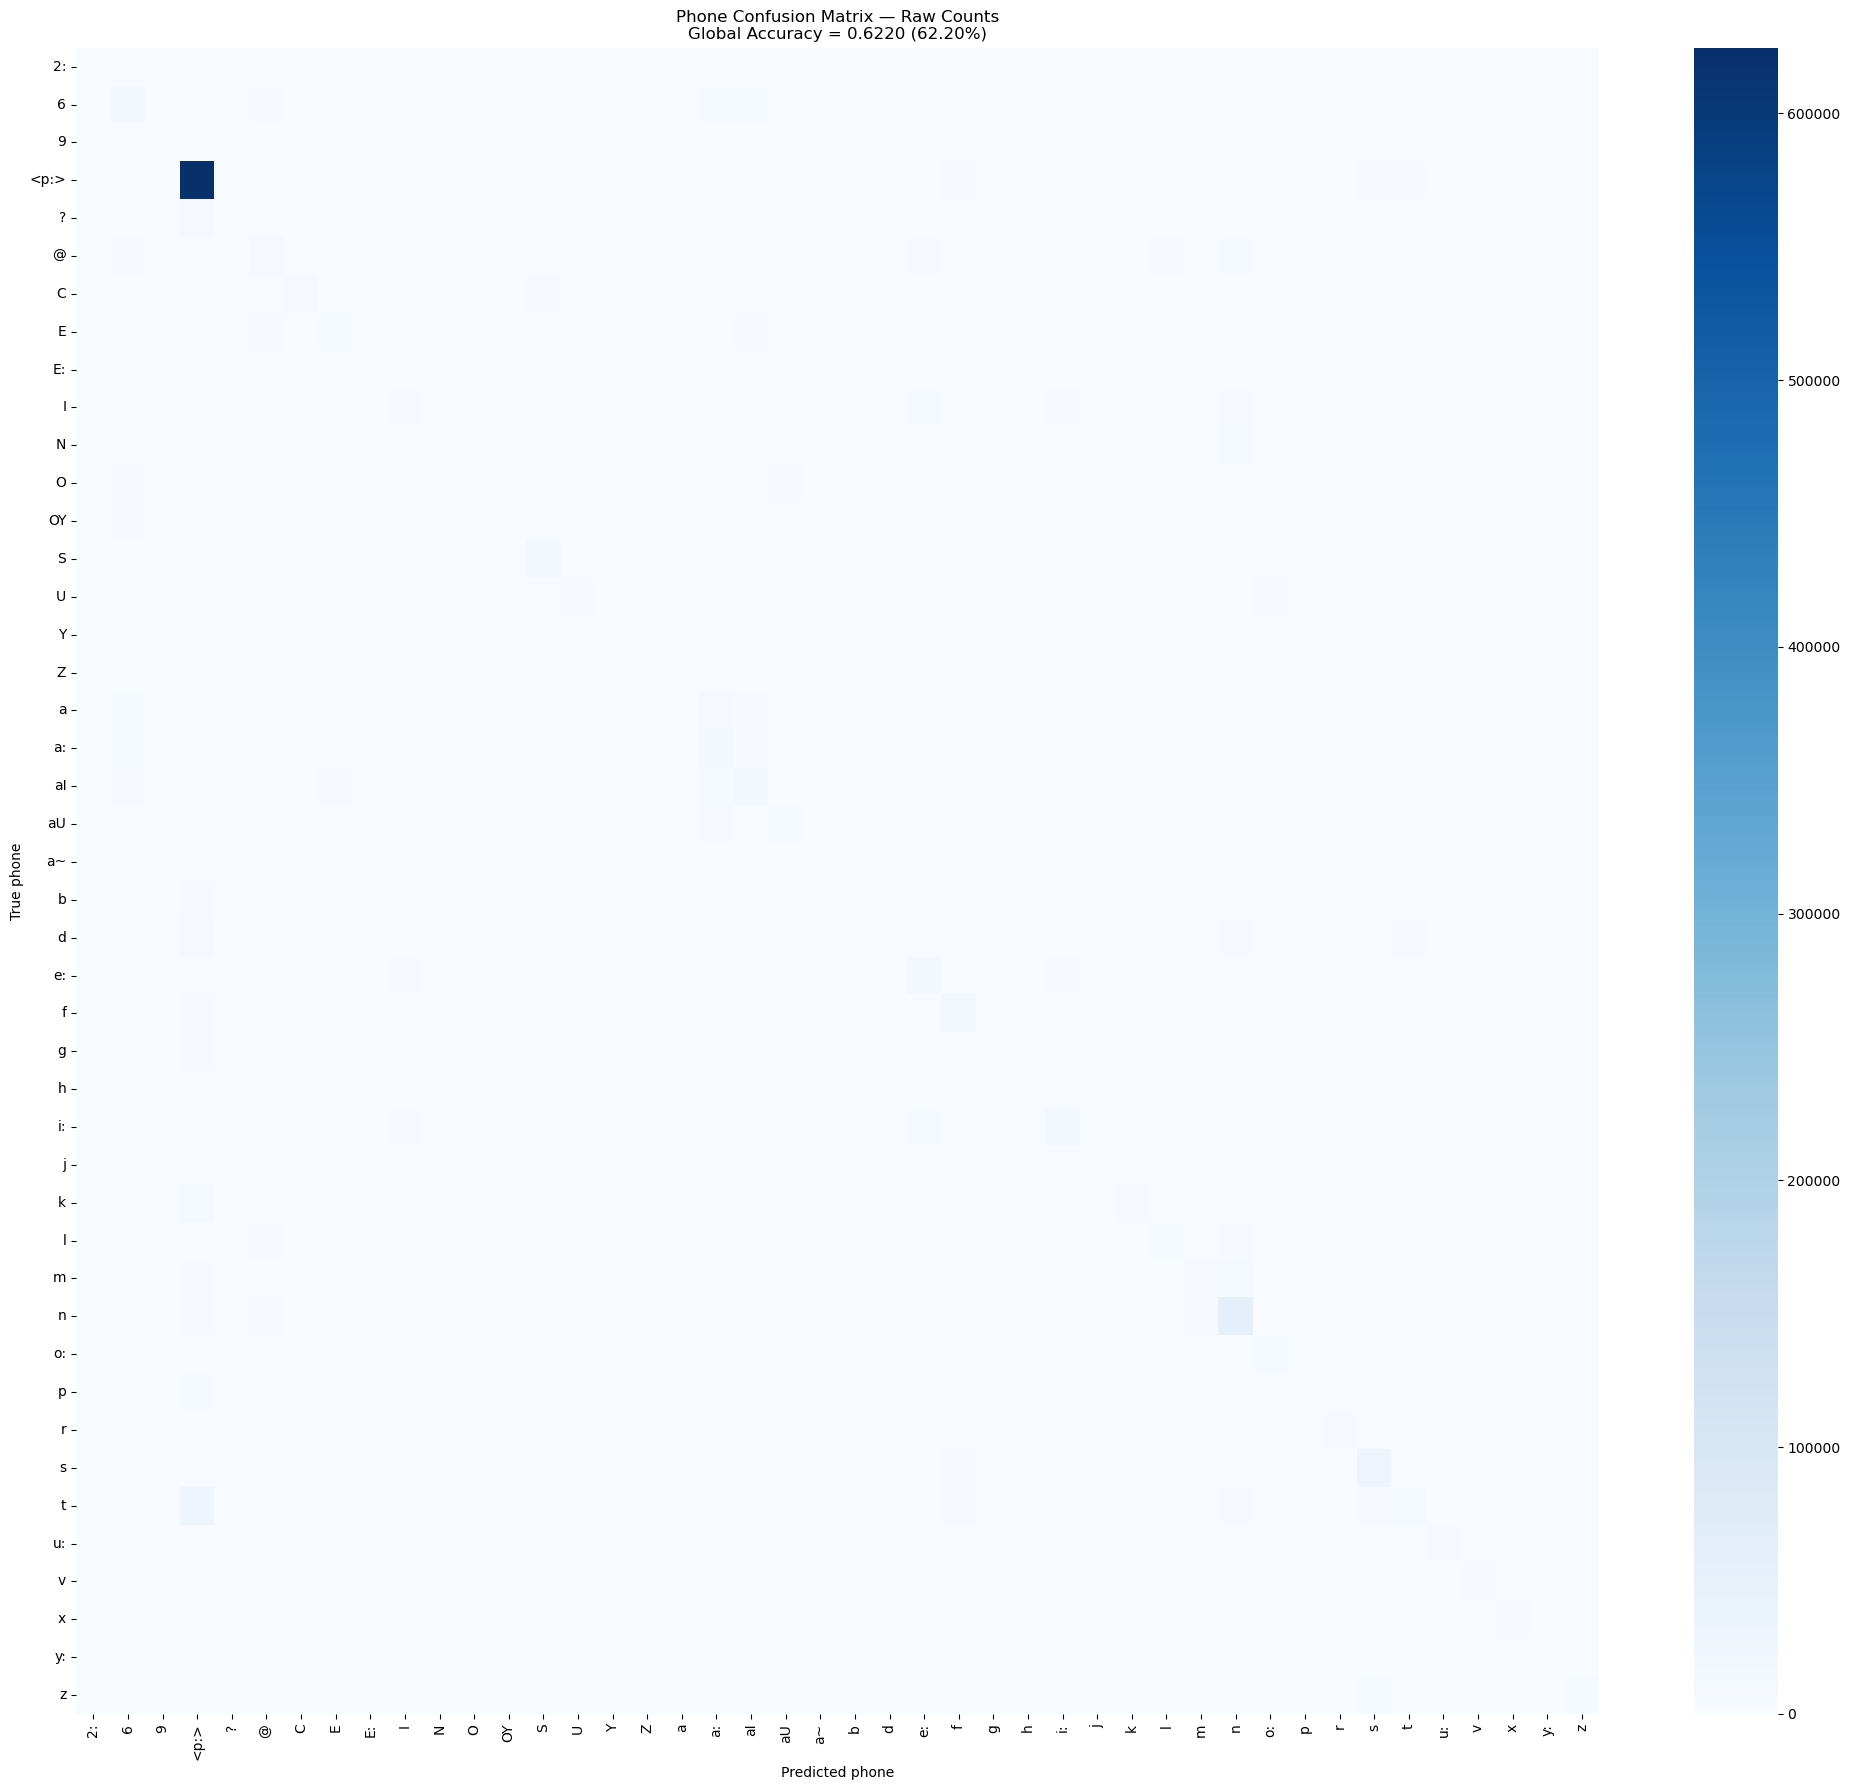

In [26]:
# plot the raw confusion matrix as a heatmap and save it as a png image
# the matrix here is not normalized, so the value in each cell represents the actual number of frames
plt.figure(figsize=(20, 18))

sns.heatmap(cm, xticklabels=phone_names, yticklabels=phone_names, cmap="Blues", annot=False)

# cm[true_phone_id, predicted_phone_id]
plt.xlabel("Predicted phone")
plt.ylabel("True phone")
plt.title(
    f"Phone Confusion Matrix — Raw Counts\n"
    f"Global Accuracy = {test_accuracy:.4f} "
    f"({test_accuracy * 100:.2f}%)"
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

raw_cm_path = os.path.join(evaluation_directory, "confusion_matrix_raw.png")

plt.savefig(raw_cm_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

- This heatmap shows the row-normalized confusion matrix.

- Each row sums to 1, so the values show the prediction distribution for each true phone.

- This makes it easier to compare phones with different numbers of test frames.

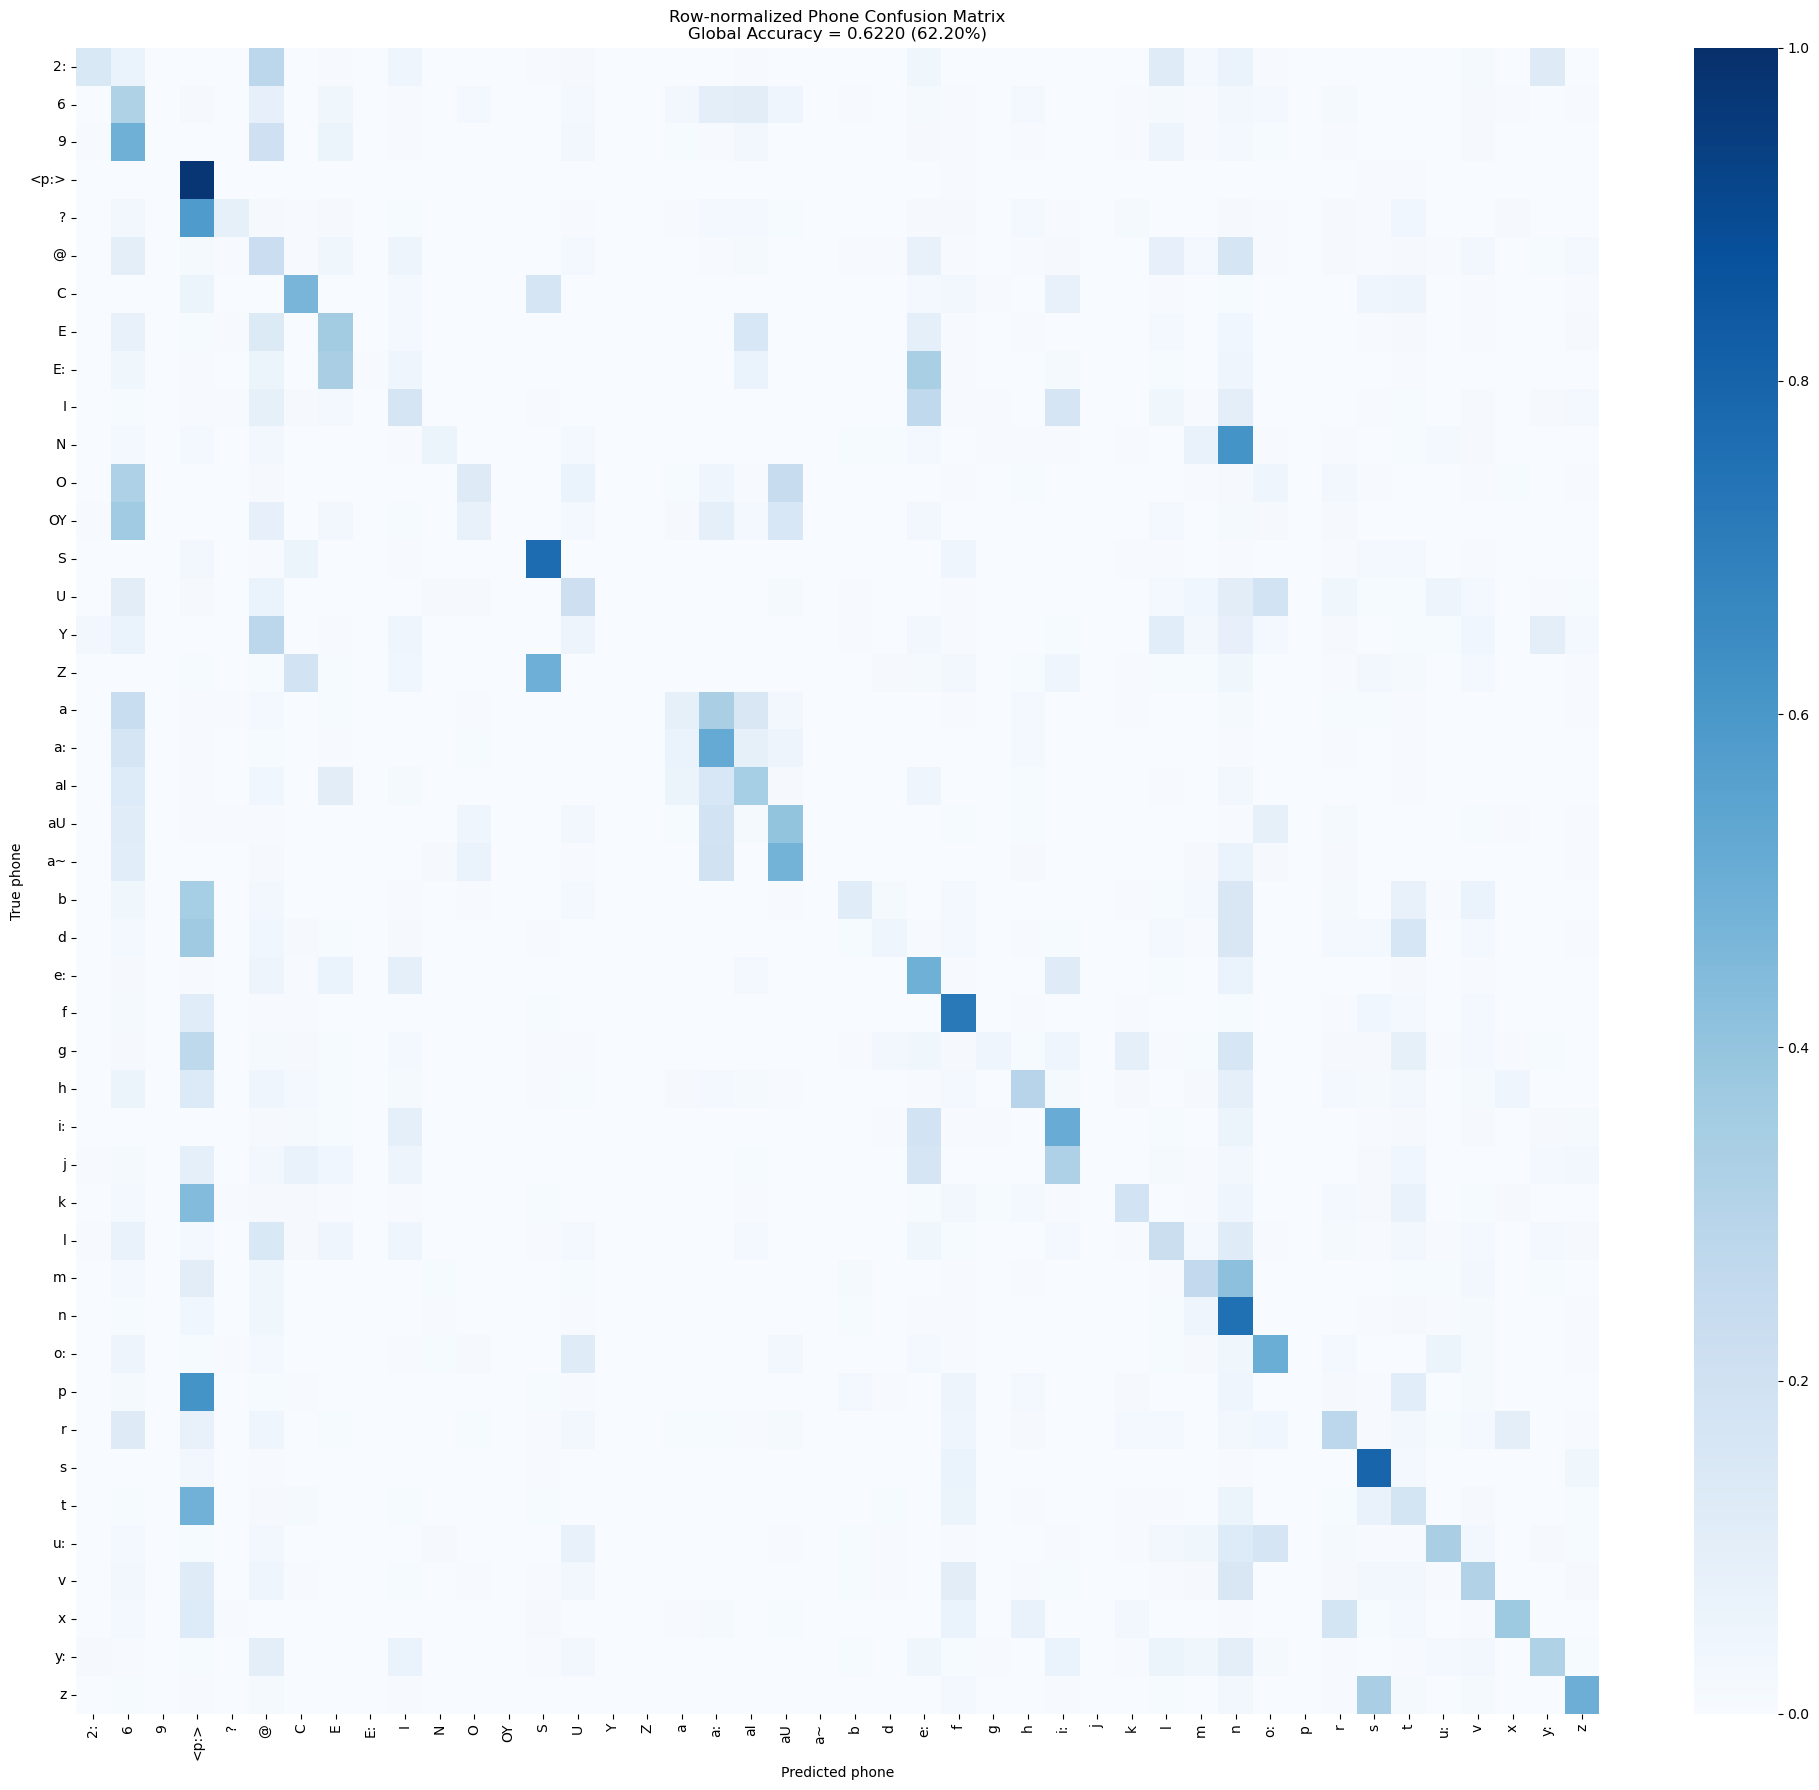

In [27]:
# normalize the raw confusion matrix row-wise based on the golden label
# then plot the normalized heatmap
row_totals = cm.sum(axis=1, keepdims=True) # (num_classes, 1)

cm_normalized = np.divide(cm, row_totals, out=np.zeros_like(cm, dtype=np.float64), where=(row_totals != 0))

plt.figure(figsize=(20, 18))

# do not display numbers in each cell, values from 0 to 1
sns.heatmap(cm_normalized, xticklabels=phone_names, yticklabels=phone_names, 
            cmap="Blues", vmin=0, vmax=1, annot=False)

plt.xlabel("Predicted phone")
plt.ylabel("True phone")
plt.title(
    f"Row-normalized Phone Confusion Matrix\n"
    f"Global Accuracy = {test_accuracy:.4f} "
    f"({test_accuracy * 100:.2f}%)"
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

normalized_cm_path = os.path.join(evaluation_directory, "confusion_matrix_normalized.png")

plt.savefig(normalized_cm_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

- We save per-phone recall and precision to a CSV file, print the phones with the highest and lowest recall.

- Low recall indicates phones that the model often fails to recognize correctly.

In [28]:
phone_results_df = distribution_df[["phone", "true_sum", "correct_predictions", "recall", "precision"]].copy()
phone_results_df = phone_results_df.sort_values(by="recall", ascending=False, na_position="last")

phone_results_path = os.path.join(evaluation_directory, "per_phone_results.csv")

phone_results_df.to_csv(phone_results_path, index=False, encoding="utf-8")

print("\nPhones with highest recall:")
print(
    phone_results_df.nlargest(10, "recall").to_string(
        index=False,
        formatters={
            "recall": lambda x: f"{x * 100:.2f}%",
            "precision": lambda x: f"{x * 100:.2f}%"
        }
    )
)

print("\nPhones with lowest recall:")
print(
    phone_results_df
    .dropna(subset=["recall"])
    .nsmallest(10, "recall")
    .to_string(
        index=False,
        formatters={
            "recall": lambda x: f"{x * 100:.2f}%",
            "precision": lambda x: f"{x * 100:.2f}%"
        }
    )
)


Phones with highest recall:
phone  true_sum  correct_predictions recall precision
 <p:>    641112               624650 97.43%    86.64%
    s     42290                33632 79.53%    62.82%
    S     20979                16069 76.60%    70.22%
    n     78883                59171 75.01%    47.99%
    f     27885                20075 71.99%    49.83%
   a:     29127                15111 51.88%    36.09%
   i:     27999                14320 51.14%    47.30%
   o:     13854                 6980 50.38%    41.06%
    z     14470                 7211 49.83%    48.13%
   e:     32406                15825 48.83%    36.71%

Phones with lowest recall:
phone  true_sum  correct_predictions recall precision
    Z       248                    0  0.00%     0.00%
    p      9287                    0  0.00%     0.00%
    9      2343                    0  0.00%     0.00%
   a~       159                    0  0.00%     0.00%
   OY      8116                    8  0.10%    18.18%
    j      5234          

__Accuracy Excluding Pause Frames__

- This metric calculates the classification accuracy after excluding all test frames whose gold label is `<p:>`.

- The `<p:>` class contains a particularly large number of test frames and is generally easier to recognize than many speech phones. Consequently, it may have a strong influence on the global accuracy, especially when the test set is class-imbalanced.

- The accuracy excluding `<p:>` provides a supplementary measure of how well the model recognizes non-pause phones. It helps assess how strongly the frequent pause class affects the overall result.

In [29]:
pause_id = phone_names.index("<p:>")

# trace: calculate the sum of the diagonal elements of the confusion matrix
correct_without_pause = (np.trace(cm) - cm[pause_id, pause_id])

samples_without_pause = (cm.sum() - cm[pause_id].sum())
accuracy_without_pause = (correct_without_pause / samples_without_pause)

print(f"Accuracy excluding <p:>: {accuracy_without_pause:.4f} ({accuracy_without_pause * 100:.2f}%)")

pause_data = {
    "global_accuracy": float(test_accuracy),
    "accuracy_without_pause": float(accuracy_without_pause),
    "pause_label": "<p:>",
    "pause_phone_id": int(pause_id)}

pause_data_path = os.path.join(evaluation_directory, "pause_data.json")

with open(pause_data_path, "w", encoding="utf-8") as file:
    json.dump(pause_data, file, ensure_ascii=False, indent=2)

print("Pause data saved.")

Accuracy excluding <p:>: 0.3635 (36.35%)
Pause data saved.


- This section computes directional confusions.

- For each true phone, it identifies which wrong phone it is most often predicted as.

- The error rate is calculated relative to the number of frames of the true phone.

In [30]:
minimum_support = 100
directional_confusions = []

for true_id, true_phone in enumerate(phone_names):
    # reuse the previously calculated true_support array
    true_phone_support = int(true_support[true_id])

    # skip phones with too few true examples, because their error rates are unstable
    if true_phone_support < minimum_support:
        continue

    for predicted_id, predicted_phone in enumerate(phone_names):
        # skip correct predictions on the diagonal
        if true_id == predicted_id:
            continue

        count = int(cm[true_id, predicted_id])
        error_rate = count / true_phone_support * 100

        directional_confusions.append({
            "true_phone": true_phone,
            "predicted_phone": predicted_phone,
            "count": count,
            "true_phone_support": true_phone_support,
            "error_rate": error_rate
        })

directional_confusions_df = pd.DataFrame(directional_confusions).sort_values(
    by=["error_rate", "count"],
    ascending=[False, False]
)

directional_path = os.path.join(evaluation_directory, "directional_confusions.csv")
directional_confusions_df.to_csv(directional_path, index=False, encoding="utf-8")

print("Directional confusions with highest error rates:")
print(
    directional_confusions_df.head(20).to_string(
        index=False,
        formatters={
            "error_rate": "{:.2f}%".format
        }
    )
)

Directional confusions with highest error rates:
true_phone predicted_phone  count  true_phone_support error_rate
         N               n   5300                8618     61.50%
         p            <p:>   5711                9287     61.49%
         ?            <p:>   9754               16661     58.54%
         Z               S    123                 248     49.60%
         9               6   1145                2343     48.87%
         t            <p:>  31136               63890     48.73%
        a~              aU     76                 159     47.80%
         k            <p:>  10611               23976     44.26%
         m               n  11879               28173     42.16%
         d            <p:>   9271               24917     37.21%
        OY               6   2963                8116     36.51%
         b            <p:>   4050               11631     34.82%
        E:              e:   1249                3655     34.17%
         a              a:   9480        

- This section analyzes pairwise phone confusions. (no specific directions)

- For each pair of phones, it combines errors in both directions: A predicted as B and B predicted as A.

- Phones with very low support are skipped, because small counts can make error rates misleading. (more bigger)

In [31]:
minimum_support = 100 # if golden account too low, it will mislead the result
phone_pair_results = []

for phone_a_id in range(num_classes):

    # get phone a's name and support
    phone_a = phone_names[phone_a_id]
    support_a = int(true_support[phone_a_id])

    # skip every pair containing phone a if its support is too small
    if support_a < minimum_support:
        continue

    for phone_b_id in range(phone_a_id + 1, num_classes):
        # starting from phone_a_id + 1 avoids self-pairs and duplicates

        # get phone b's name and support
        phone_b = phone_names[phone_b_id]
        support_b = int(true_support[phone_b_id])

        # skip the current pair if phone b has insufficient support
        if support_b < minimum_support:
            continue

        # get the total count of: true a, predicted as b
        a_as_b = int(cm[phone_a_id, phone_b_id])
        # get the total count of: true b, predicted as a
        b_as_a = int(cm[phone_b_id, phone_a_id])

        # see a and b as a pair, get the total count of false prediction: pair a-b
        total_pair_confusions = a_as_b + b_as_a
        # count of total golden label
        total_support = support_a + support_b

        pair_confusion_rate = (total_pair_confusions / total_support *100
                               if total_support > 0
                               else np.nan) # avoid 0 division error
        
        a_as_b_rate = a_as_b / support_a * 100
        b_as_a_rate = b_as_a / support_b * 100

        phone_pair_results.append({
            "phone_a": phone_a,
            "phone_b": phone_b,
            "support_a": support_a,
            "support_b": support_b,
            "a_predicted_as_b": a_as_b,
            "b_predicted_as_a": b_as_a,
            "a_as_b_rate": a_as_b_rate,
            "b_as_a_rate": b_as_a_rate,
            "total_pair_confusions": total_pair_confusions,
            "pair_confusion_rate": pair_confusion_rate
        })

phone_pair_df = pd.DataFrame(phone_pair_results)

phone_pair_df = phone_pair_df.sort_values(
    by=["pair_confusion_rate", "total_pair_confusions"],
    ascending=[False, False]
)

pair_results_path = os.path.join(evaluation_directory, "phone_pair_confusions.csv")
phone_pair_df.to_csv(pair_results_path, index=False, encoding="utf-8")

print("Phone pairs that are most difficult to distinguish:")
print(
    phone_pair_df.head(20).to_string(
        index=False,
        formatters={
            "a_as_b_rate": "{:.2f}%".format,
            "b_as_a_rate": "{:.2f}%".format,
            "pair_confusion_rate": "{:.2f}%".format
        }
    )
)

Phone pairs that are most difficult to distinguish:
phone_a phone_b  support_a  support_b  a_predicted_as_b  b_predicted_as_a a_as_b_rate b_as_a_rate  total_pair_confusions pair_confusion_rate
      a      a:      27984      29127              9480              1907      33.88%       6.55%                  11387              19.94%
      I      e:      26396      32406              7088              3055      26.85%       9.43%                  10143              17.25%
      U      o:      13213      13854              2478              1714      18.75%      12.37%                   4192              15.49%
     e:      i:      32406      27999              4036              5311      12.45%      18.97%                   9347              15.47%
      m       n      28173      78883             11879              3483      42.16%       4.42%                  15362              14.35%
      r       x      14701      10203              1470              1870      10.00%      18.33%     

- This plot shows how training loss and validation loss change over epochs.

- The dashed vertical line marks the epoch with the best validation loss.

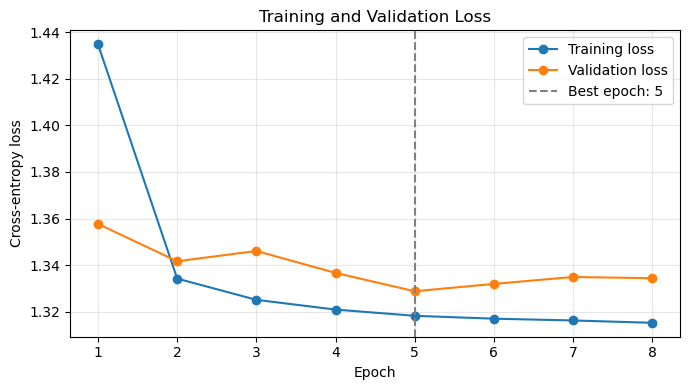

In [32]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(7, 4))

# training loss
plt.plot(epochs, history["train_loss"], marker="o", label="Training loss")
# validation loss
plt.plot(epochs, history["validation_loss"], marker="o", label="Validation loss")
# mark best epoch
plt.axvline(x=best_epoch, color="gray", linestyle="--", label=f"Best epoch: {best_epoch}")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training and Validation Loss")

plt.xticks(epochs)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

loss_curve_path = os.path.join(evaluation_directory, "training_validation_loss.png")
plt.savefig(loss_curve_path, dpi=300, bbox_inches="tight")

plt.show()
plt.close()

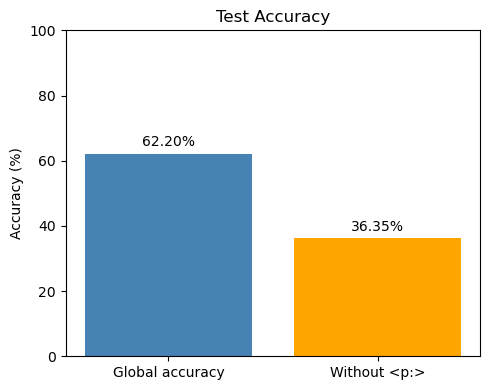

In [33]:
accuracy_names = ["Global accuracy", "Without <p:>"]

accuracy_values = [test_accuracy * 100, accuracy_without_pause * 100]

plt.figure(figsize=(5, 4))

bars = plt.bar(accuracy_names, accuracy_values, color=["steelblue", "orange"])

plt.ylabel("Accuracy (%)")
plt.title("Test Accuracy")
plt.ylim(0, 100)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()

plt.savefig(os.path.join(evaluation_directory, "test_accuracy_comparison.png"),
    dpi=300,
    bbox_inches="tight")

plt.show()
plt.close()

In [34]:
highest_recall_table = (phone_results_df.dropna(subset=["recall"]).nlargest(10, "recall")
    [[
        "phone",
        "true_sum",
        "recall",
        "precision"
    ]].copy())

highest_recall_table["recall"] *= 100
highest_recall_table["precision"] *= 100

highest_recall_table = highest_recall_table.rename(
    columns={
        "true_sum": "support",
        "recall": "recall (%)",
        "precision": "precision (%)"})

highest_recall_table = highest_recall_table.round(2)

display(highest_recall_table)

,phone,support,recall (%),precision (%)
3,<p:>,641112,97.43,86.64
37,s,42290,79.53,62.82
13,S,20979,76.60,70.22
33,n,78883,75.01,47.99
25,f,27885,71.99,49.83
18,a:,29127,51.88,36.09
28,i:,27999,51.14,47.30
34,o:,13854,50.38,41.06
43,z,14470,49.83,48.13
24,e:,32406,48.83,36.71


In [35]:
directional_table = (directional_confusions_df.nlargest(10, "error_rate")
    [[
        "true_phone",
        "predicted_phone",
        "count",
        "true_phone_support",
        "error_rate"
    ]].copy())

directional_table = directional_table.rename(
    columns={
        "true_phone": "true",
        "predicted_phone": "predicted",
        "true_phone_support": "support",
        "error_rate": "error rate (%)"})

directional_table = directional_table.round(2)

display(directional_table)

,true,predicted,count,support,error rate (%)
462,N,n,5300,8618,61.50
1508,p,<p:>,5711,9287,61.49
175,?,<p:>,9754,16661,58.54
701,Z,S,123,248,49.60
87,9,6,1145,2343,48.87
1637,t,<p:>,31136,63890,48.73
923,a~,aU,76,159,47.80
1293,k,<p:>,10611,23976,44.26
1408,m,n,11879,28173,42.16
992,d,<p:>,9271,24917,37.21


In [36]:
phone_pair_table = (phone_pair_df.nlargest(10, "pair_confusion_rate")
    [[
        "phone_a",
        "phone_b",
        "a_as_b_rate",
        "b_as_a_rate",
        "pair_confusion_rate"
    ]].copy())

phone_pair_table = phone_pair_table.rename(
    columns={
        "phone_a": "phone A",
        "phone_b": "phone B",
        "a_as_b_rate": "A → B (%)",
        "b_as_a_rate": "B → A (%)",
        "pair_confusion_rate": "combined (%)"
    }
)

phone_pair_table = phone_pair_table.round(2)

display(phone_pair_table)

,phone A,phone B,A → B (%),B → A (%),combined (%)
595,a,a:,33.88,6.55,19.94
365,I,e:,26.85,9.43,17.25
530,U,o:,18.75,12.37,15.49
759,e:,i:,12.45,18.97,15.47
880,m,n,42.16,4.42,14.35
922,r,x,10.00,18.33,13.41
369,I,i:,17.16,9.10,13.01
621,a:,aI,8.90,15.89,12.79
59,6,a:,10.15,17.09,12.64
291,E,aI,15.70,10.56,12.38
